# IAU Projekt - fáza 3
**Marek Kujan Privrel** a **Martin Benko** (rozdelenie práce 50:50)  
Cvičenie: Utorok 16:00 s Ing. Laurou Krajčovičovou  

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import statsmodels.api as sm
import statsmodels.stats as sm_stats
import sklearn
import category_encoders as ce

from pprint import pprint


In [44]:
train_df = pd.read_csv("train_preprocessed.csv")
test_df = pd.read_csv("test_preprocessed.csv")



# 1. Separate the majority and minority classes in your TRAINING data
df_majority = train_df[train_df['failure'] == 0]
df_minority = train_df[train_df['failure'] == 1]

# 2. Randomly sample the majority class to match the minority class count
df_majority_undersampled = df_majority.sample(
    n=len(df_minority), 
    random_state=1  # Ensures reproducibility
)

# 3. Combine them back together and shuffle the rows
df_train_balanced = pd.concat([df_majority_undersampled, df_minority])
train_df = df_train_balanced.sample(frac=1, random_state=42).reset_index(drop=True)


## 3.1 Jednoduchý klasifikátor na základe závislosti v dátach

Kód nižšie definuje našu vlastnú implementáciu ID3 algoritmu, ktorý buduje rozhodovací strom na základe entropie, resp. information gain potencionálnych podstromov. 
- **trieda Node** definuje uzol v rozhodovacom strome. Má vlastné metódy, väčšina z nich sú len pomocné, no tá hlavná je metóda **live_and_make_children()** ktorá rekurzívne buduje ďalšie uzly stromu podľa zvoleného najvýhodnejšieho atribútu.  
- **trieda ID3_Classifier** potom len prepája logiku jednotlivých uzlov tak, aby sa dali použiť pre vybudovanie stromu (metóda **train()**), prehľadávanie stromu pre predikovanie výsledku `failure` pomocou metódy **predict()**, alebo hromadné otestovanie výsledkov nad dátami cez funkciu **test()**.

In [6]:
def define_ranges(unique_values) -> dict:
    unique_values = pd.Series(unique_values).sort_values(ascending=True)
    cuts = (unique_values + unique_values.shift(1))/2
    cuts = cuts.to_list()[1:]
    
    output = {}
    for n in range(len(cuts)+1):
        output[n] = {
            "low_boundry": -np.inf if n == 0 else cuts[n-1],
            "high_boundry": np.inf if n == len(cuts) else cuts[n],
            "child_node": "-"
        }

    return output

def calc_entropy(data: pd.DataFrame): # vypočíta entropiu pre data
        p = data["failure"].value_counts(normalize=True)
        return abs((p * np.log2(p)).sum())

In [7]:
class Node():
    def __init__(self, data: pd.DataFrame, attribute_types: dict, depth: int, max_depth: int):
        self.data = data
        self.attribute_types = attribute_types
        self.depth = depth
        self.max_depth = max_depth
        self.final = False
        self.entropy = calc_entropy(self.data)
        self.children = {}   # 0: {"low_boundry": , "high_boundry": , "child_node": Node()}
        self.attribute = None
        self.prediction = None


    def pick_best_attribute(self) -> tuple:
        cols = self.data.columns.to_list()
        cols.pop(cols.index("failure"))

        best_ig = 0
        best_attr = None
        best_split_point = None

        for col in cols:
            ig, split_point = self.try_attribute(col)
            if ig > best_ig:
                best_ig = ig
                best_attr = col
                best_split_point = split_point

        return best_attr, best_split_point

    def live_and_make_children(self):
        self.prediction = round(self.data["failure"].mean())

        if self.depth == self.max_depth:
            self.final = True
            return

        if self.entropy == 0:
            self.final = True
            return

        self.attribute, split_point = self.pick_best_attribute()
        if self.attribute == None:
            self.final = True
            return

        if split_point == None:   # kategorický atribút
            self.children = define_ranges(self.data[self.attribute].unique())

        else:                     # numerický atribút
            self.children = {
                0: { "low_boundry": -np.inf, "high_boundry": split_point, "child_node": "-"},
                1: { "low_boundry": split_point, "high_boundry": np.inf, "child_node": "-"}
            }
            
        for val in self.children.values():
            column = self.data[self.attribute]
            
            child_data = self.data.loc[(column > val["low_boundry"]) & (column <= val["high_boundry"])]

            if split_point is None:     # odstraňujem len kategorické atribúty, numerické ešte môžu poslúžiť
                child_data = child_data.drop(columns=self.attribute)

            val["child_node"] = Node(child_data, self.attribute_types, self.depth+1, self.max_depth)
            val["child_node"].live_and_make_children()

            
    """def try_attribute(self, attribute: str) -> tuple:

        if self.attribute_types[attribute] == "categorical":      # Kategorické atribúty == nunique pod 100 hodnôt spracujeme podľa ID3 algoritmu

            categories = pd.DataFrame(self.data[attribute].value_counts(normalize=True))

            for category in categories.index.to_list():
                categories.loc[category, "entropy"] = calc_entropy(self.data.loc[self.data[attribute] == category])

            categories["product"] = categories.entropy * categories.proportion
            
            weighted_entropy = abs(np.sum(categories["product"]))
            info_gain = self.entropy - weighted_entropy
            return info_gain, None

            
        
        # Spojité atribúty - hľadáme najlepší split point, podľa ktorého bude info_gain najlepší

        temp = self.data[[attribute, "failure"]].sort_values(by=attribute)
        temp["middle"] = (temp[attribute] + temp[attribute].shift(1)) / 2

        thresholds = temp.loc[temp[attribute] != temp[attribute].shift(1), "middle"].dropna()

        thresholds = pd.DataFrame({"threshold": thresholds})

        if thresholds.empty:
            return 0, None

        thresholds["percentage_left"] = thresholds["threshold"].apply(lambda t: (temp[attribute] <= t).mean())
        thresholds["percentage_right"] = 1 - thresholds["percentage_left"]

        thresholds["entropy_left"] = thresholds["threshold"].apply(lambda t: calc_entropy(temp[temp[attribute] <= t]))
        thresholds["entropy_right"] = thresholds["threshold"].apply(lambda t: calc_entropy(temp[temp[attribute] > t]))

        thresholds["weighted_entropy"] = (thresholds["percentage_left"] * thresholds["entropy_left"] + thresholds["percentage_right"] * thresholds["entropy_right"])

        best_index = thresholds["weighted_entropy"].idxmin()
        info_gain = self.entropy - thresholds.at[best_index, "weighted_entropy"]
        best_split_point = thresholds.at[best_index, "threshold"]

        return info_gain, best_split_point"""

    def try_attribute(self, attribute):
        if self.attribute_types[attribute] == "categorical":
            g = self.data.groupby(attribute)["failure"].agg(["mean", "size"])
            p1 = g["mean"].to_numpy()
            with np.errstate(divide="ignore", invalid="ignore"):
                e = -(np.where(p1 > 0, p1 * np.log2(p1), 0) +
                    np.where(p1 < 1, (1 - p1) * np.log2(1 - p1), 0))
            weighted_entropy = (e * g["size"].to_numpy()).sum() / len(self.data)
            return self.entropy - weighted_entropy, None

        x = self.data[attribute].to_numpy()
        y = self.data["failure"].to_numpy()

        order = np.argsort(x, kind="stable")
        x = x[order]
        y = y[order]
        n = len(y)

        # kandidátske rezy: len tam, kde sa hodnota mení
        change = np.nonzero(x[1:] != x[:-1])[0]      # index posledného prvku ľavej časti
        if change.size == 0:
            return 0, None

        cum_pos = np.cumsum(y)
        total_pos = cum_pos[-1]

        n_left = change + 1
        n_right = n - n_left
        pos_left = cum_pos[change]
        pos_right = total_pos - pos_left

        def ent(pos, cnt):
            p1 = pos / cnt
            p0 = 1 - p1
            with np.errstate(divide="ignore", invalid="ignore"):
                e = -(np.where(p1 > 0, p1 * np.log2(p1), 0) +
                    np.where(p0 > 0, p0 * np.log2(p0), 0))
            return e

        weighted = (n_left * ent(pos_left, n_left) + n_right * ent(pos_right, n_right)) / n

        best = np.argmin(weighted)
        split_point = (x[change[best]] + x[change[best] + 1]) / 2
        return self.entropy - weighted[best], split_point
    
    def find_range(self, value):
        for key, val in self.children.items():
            if value <= val["high_boundry"]:
                if value > val["low_boundry"]:
                    return key

        raise Exception("Function 'find_range()' somehow could not find the range!")
    


In [8]:
class ID3_Classifier():
    def __init__(self, max_depth: int = 10):
        self.root = None
        self.max_depth = max_depth

    def train(self, data: pd.DataFrame):
        attribute_types = {}
        for attr in data.columns.to_list():
            attribute_types[attr] = "categorical" if data[attr].nunique() < 100 else "numeric"
        
        self.root = Node(data, attribute_types, 1, self.max_depth)
        self.root.live_and_make_children()

    def test(self, data: pd.DataFrame):
        fn, fp, tn, tp = 0, 0, 0, 0
        for row_num in range(len(data)):
            row = data.loc[row_num]
            prediction = self.predict(row)
            if prediction == 1:
                if row["failure"] == 1:
                    tp += 1
                else:
                    fp += 1
            else:
                if row["failure"] == 1:
                    fn += 1
                else:
                    tn += 1
        return fn, fp, tn, tp


    def predict(self, test_vector):
        crossroad = self.root
        while not crossroad.final:
            index = crossroad.find_range(test_vector[crossroad.attribute])
            crossroad = crossroad.children[index]["child_node"]

        return crossroad.prediction



Bez akéhohoľvek pruningu algoritmus na našich testovacích dátach `test_df` dosiahol hodnoty `Accuracy = 79.65 %`, `Precision: 20.58 %` a `Recall: 22.16 %`. Otestovali sme ho aj na `train_df`, aby sme si overili či bol správne vytvorený, a teraz vieme že bol, lebo mal všetky 3 metriky na 100 %. Znamená to teda, že je veľmi pretrénovaný a musíme implementovať techniky ako pre-pruning, teda obmedzenie hĺbky stromu. to by nám malo zhoršiť výsledky pre `train_df` a snáď výrazne zlepšiť metriky `test_df`. Priamo úmerne by sme sa mali zlepšiť aj časy budovania stromu.

In [39]:
runs = {n:{"Accuracy":0, "Precision":0, "Recall":0} for n in range (2, 30, 2)}


In [53]:
for key, value in runs.items():
    id3 = ID3_Classifier(key)
    id3.train(train_df)

    fn, fp, tn, tp = id3.test(test_df)
    value["Accuracy"] = (tn+tp)/(fn+fp+tn+tp)*100
    value["Precision"] = (tp)/(fp+tp)*100 if (fp+tp) != 0 else 0
    value["Recall"] = (tp)/(fn+tp)*100 if (fn+tp) != 0 else 0
    # print(f"Depth = {key}")

     accuracy  precision     recall
2   61.783439  17.901235  57.670455
4   67.020524  20.588235  57.670455
6   65.003539  18.054162  51.136364
8   59.200283  16.088061  53.977273
10  58.174098  15.645695  53.693182
12  58.669498  15.365025  51.420455
14  56.970984  15.048544  52.840909
16  56.935598  14.922952  52.272727
18  56.652512  14.883347  52.556818
20  56.263270  14.920635  53.409091
22  56.334041  14.944356  53.409091
24  56.334041  14.944356  53.409091
26  56.334041  14.944356  53.409091
28  56.334041  14.944356  53.409091


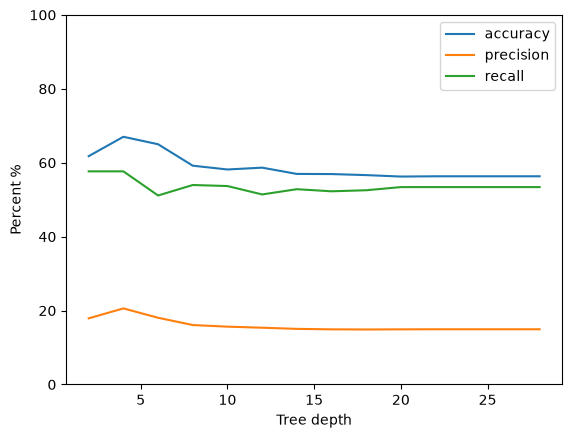

In [54]:
plot_df = pd.DataFrame({
    "accuracy": [i["Accuracy"] for i in runs.values()],
    "precision": [i["Precision"] for i in runs.values()],
    "recall": [i["Recall"] for i in runs.values()]
}, index=[i for i in runs.keys()])
print(plot_df)
plt.plot(plot_df)
plt.legend(plot_df.columns)
plt.xlabel("Tree depth")
plt.ylabel("Percent %")
plt.yticks(range(0,101, 20))
plt.show()